# SIIM-ISIC 
Data source: https://www.kaggle.com/competitions/siim-isic-melanoma-classification

# Import Lib & Config

In [1]:
pip install -U kaleido

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.2/138.2 kB 8.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Data Manipulation
import numpy as np 
import pandas as pd 
from tabulate import tabulate

# Viz
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno                
from IPython.display import display as ipyDisplay, HTML, Markdown

import random

# Model
import tensorflow as tf

# Image Processing
import cv2
from PIL import Image
# Datetime 
from datetime import datetime
# Statistic
from scipy.stats import norm, probplot, skew, kurtosis, entropy

# Common 
import os
from tqdm import tqdm

In [3]:
sns.set(style="whitegrid")

prefix_bold = r'$\bf{'
suffix_bold = '}$'

'''Set color palette
denotes:
    - black for 0 (benign)
    - red for ๅ (malignant)
'''
palette = {0: 'black', 
           1: 'red'}

# Data Check-up

In [4]:
jpeg_path = '/kaggle/input/siim-isic-melanoma-classification/jpeg'

## Structured_data

In [5]:
test_df = pd.read_csv('/kaggle/input/siim-isic-melanoma-classification/test.csv')
test_df

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge
0,ISIC_0052060,IP_3579794,male,70.0,NaN
1,ISIC_0052349,IP_7782715,male,40.0,lower extremity
2,ISIC_0058510,IP_7960270,female,55.0,torso
3,ISIC_0073313,IP_6375035,female,50.0,torso
4,ISIC_0073502,IP_0589375,female,45.0,lower extremity
...,...,...,...,...,...
10977,ISIC_9992485,IP_4152479,male,40.0,torso
10978,ISIC_9996992,IP_4890115,male,35.0,torso
10979,ISIC_9997917,IP_2852390,male,25.0,upper extremity
10980,ISIC_9998234,IP_8861963,male,65.0,lower extremity


In [6]:
train_df = pd.read_csv('/kaggle/input/siim-isic-melanoma-classification/train.csv')
train_df

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0
...,...,...,...,...,...,...,...,...
33121,ISIC_9999134,IP_6526534,male,50.0,torso,unknown,benign,0
33122,ISIC_9999320,IP_3650745,male,65.0,torso,unknown,benign,0
33123,ISIC_9999515,IP_2026598,male,20.0,lower extremity,unknown,benign,0
33124,ISIC_9999666,IP_7702038,male,50.0,lower extremity,unknown,benign,0


In [7]:
def explicit(func):
    func.is_explicit = True
    return func


def implicit(func):
    func.is_implicit = True
    return func


class HealthCheck:
    def __init__(self, cmap: str = "Greys"):
        self.cmap = cmap

    @explicit
    def msno_bar(self, data: pd.DataFrame):
        return msno.bar(data)

    @explicit
    def msno_matrix(self, data: pd.DataFrame):
        return msno.matrix(data)

    @explicit
    def msno_heatmap(self, data: pd.DataFrame):
        return msno.heatmap(data)

    @explicit
    def msno_dendrogram(self, data: pd.DataFrame):

        max_text = 50
        print("-" * max_text)
        print("\033[1mDendrogram\033[0m")
        print("-" * max_text)
        text = "dendrogram The dendrogram allows you to more fully correlate variable completion, revealing trends deeper than the pairwise ones visible in the correlation heatmap:"

        lines = [text[i : i + max_text] for i in range(0, len(text), max_text)]
        for line in lines:
            print(line)
        print("-" * max_text)
        return msno.dendrogram(data)

    def msno_multivariate(self, data: pd.DataFrame):
        return msno.multivariate(data)

    @explicit
    def stat(self, data: pd.DataFrame):
        return data.describe().T.round(2)

    @explicit
    def dtype_check(self, data: pd.DataFrame):
        ax = data.dtypes.value_counts().plot(kind="bar", color="grey")
        for p in ax.patches:
            ax.annotate(
                f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2.0, p.get_height()),
                ha="center",
                va="center",
                xytext=(0, 9),
                textcoords="offset points",
            )
        plt.show()

    @explicit
    def _get_least_most(self, data: pd.DataFrame, col: str):
        """Find least and most frequent values in a column."""
        value_counts = data[col].value_counts()
        if len(value_counts) == 0:
            return None, None
        least = (
            value_counts.index[-1] if len(value_counts) > 1 else value_counts.index[0]
        )
        most = value_counts.index[0]
        return least, most

    @implicit
    def _count_outliers(
        self, data: pd.DataFrame, col: str, method: str = "IQR", alpha: float = 0.05
    ):
        """
        Parameters:
            - alpha: is value of threshold wanted to determined in different cases, For example:
                - IQR: typical using 1.0 - 1.5
                - Z-score: typical using 0.05, which mean 5% divided by 2 for left (2.5%) and right (2.5%) of distribution to trim to outliers
                    - z_threshold = norm.ppf(1 - (alpha / 2))
        """

        if np.issubdtype(data[col].dtype, np.number) and data[col].dtype != bool:
            if method == "IQR":
                # IQR Method
                q1 = data[col].quantile(0.25)
                q3 = data[col].quantile(0.75)
                iqr = q3 - q1
                lower_bound = q1 - alpha * iqr
                upper_bound = q3 + alpha * iqr
                return len((data[col] < lower_bound) | (data[col] > upper_bound))

            elif method == "Z-score":
                # Z-score Method
                mean = data[col].mean()
                std = data[col].std()
                z_scores = np.abs(
                    (data[col] - mean) / std
                )  # Require take absolute value to avoid negative value

                z_threshold = norm.ppf(
                    1 - (alpha / 2)
                )  # divide by 2 for left (2.5%) and right (2.5%)

                """
                Note z_threshold: 
                    - norm.ppf function: ppf(q, loc=0, scale=1), Percent point function is the inverse of cdf (Cumulative distribution function.)
                        - this used to calculate the threshold for outliers based on the standard normal distribution and evaluate every data point z-threshold is away from the mean of the distribution.
                """

                outliers = data[z_scores > z_threshold][col]
                return len(outliers)

        return np.nan

    @implicit
    def _get_min_max(self, data: pd.DataFrame, col: str):
        """
        Note 2025-06-10:
            - 'M' for datetime, 'biufc' for numeric
        """
        if data[col].dtype.kind in "biufcM":
            return data[col].min(), data[col].max()
        return np.nan, np.nan

    @implicit
    def _safe_nunique(self, data: pd.DataFrame, col: str):
        # Object: Datetime, String
        if data[col].dtype == "O":
            return data[col].nunique()

        # Numerical: int, float
        if isinstance(data[col].dtype, np.number):
            return data[col].nunique()

        # Series
        elif isinstance(data[col].dtype, pd.Series):
            return data[col].nunique()

        # NumPy array
        elif isinstance(data[col].dtype, np.ndarray):
            return len(list(np.nunique(data[col])))

        # List
        elif isinstance(data[col].dtype, list):
            return len(list(np.nunique(np.array(data[col]))))

        else:
            return None

    @implicit
    def _safe_duplicated(self, data: pd.DataFrame, col: str) -> pd.Series:
        if isinstance(data[col].iloc[0], (list, np.ndarray)):
            values = pd.Series(
                [
                    tuple(val) if isinstance(val, (list, np.ndarray)) else val
                    for val in data[col]
                ]
            )
            return values.duplicated(keep="first").sum()
        elif isinstance(data[col], (pd.DataFrame, pd.Series)) or np.issubdtype(
            data[col].dtype, np.number
        ):
            return data[col].duplicated(keep="first").sum()
        else:
            return None

    @implicit
    def _select_non_list_columns(self, data) -> list:
        non_list_cols = []
        for col in data.columns:
            if not isinstance(data[col].iloc[0], (list, np.ndarray)):
                non_list_cols.append(col)
        return non_list_cols

    @explicit
    def summary_tbl(
        self,
        data: pd.DataFrame,
        method="IQR",
        alpha=1.5,
        mode="all",
        n_round: int = 3,
        return_df: bool = False,
        display: bool = True,
    ) -> pd.DataFrame:
        summary = []

        if mode == "stat":
            selected_columns = [
                col
                for col in data.columns
                if np.issubdtype(data[col].dtype, np.number) and data[col].dtype != bool
            ]
        elif mode == "qual":
            selected_columns = [
                col
                for col in data.columns
                if not np.issubdtype(data[col].dtype, np.number)
                or data[col].dtype == bool
            ]
        else:
            selected_columns = data.columns

        for col in selected_columns:
            col_data = data[col]
            n_missing = data[col].isna().sum()  # .isnull()
            n_unique = self._safe_nunique(data, col)
            n_duplicated = self._safe_duplicated(data, col)
            cnt_outliers = self._count_outliers(data, col, method, alpha)
            N = len(col_data)

            col_info = {
                "dtype": col_data.dtype,
                "cnt_missing": n_missing,
                "ratio_missing": (n_missing / N) * 100,
                "n_unique": n_unique,
                "ratio_unique": (n_unique / N) * 100 if n_unique else np.nan,
                "cnt_duplicated_per_col": n_duplicated,
                "ratio_duplicated_per_col": (n_duplicated / N) * 100
                if n_duplicated
                else np.nan,
                "least": self._get_least_most(data, col)[0],
                "most": self._get_least_most(data, col)[1],
                "mean": col_data.mean()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "median": col_data.median()
                if col_data.dtype.kind in "biufc"
                else np.nan,
                "mode": col_data.mode().iloc[0]
                if not col_data.mode().empty
                else np.nan,
                "std": col_data.std()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "min": col_data.min()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "max": col_data.max()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "skewness": col_data.skew()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "kurtosis": col_data.kurtosis()
                if np.issubdtype(col_data.dtype, np.number)
                else np.nan,
                "cnt_outliers": cnt_outliers,
                "ratio_outliers": (cnt_outliers / N),
                "memory_usage_MB": col_data.memory_usage(deep=True) / 1024**2,
            }
            summary.append(col_info)

        summary_df = pd.DataFrame(summary, index=selected_columns)

        selected_cols = self._select_non_list_columns(data)
        cnt_duplicated_rows = data[selected_cols].duplicated().sum()
        memory_usage = data.memory_usage(deep=True).sum() / 1024**2

        print(
            f"Row: {data.shape[0]}, Column: {data.shape[1]}, "
            f"Memory Usage: {memory_usage:.2f} MB, Duplicate Rows: {cnt_duplicated_rows}"
        )

        if return_df:
            return summary_df.round(n_round)
        if display:
            ipyDisplay(
                Markdown(
                    tabulate(
                        summary_df.round(n_round), headers="keys", tablefmt="github"
                    )
                )
            )

    def _get_missing(self, data):

        missing_values = data.isna().sum().sort_values(ascending=False)
        percentage_missing = (missing_values / data.shape[0]) * 100

        return pd.DataFrame(
            {
                "Missing Values": missing_values,
                "Percentage Missing Values": percentage_missing,
            }
        )

    @explicit
    def missing_check(self, data, display=True, style=True, cmap="Greys", n_round=3):
        df_missing = self._get_missing(data)
        if display:
            if style:
                ipyDisplay(
                    df_missing.style.background_gradient(
                        cmap=cmap if cmap else self.cmap
                    )
                )
            else:
                ipyDisplay(
                    Markdown(
                        tabulate(
                            df_missing.round(n_round), headers="keys", tablefmt="github"
                        )
                    )
                )
        else:
            return df_missing.round(n_round)

In [8]:
HC = HealthCheck()

In [9]:
HC.summary_tbl(train_df)

Row: 33126, Column: 8, Memory Usage: 12.85 MB, Duplicate Rows: 0


|                               | dtype   |   cnt_missing |   ratio_missing |   n_unique |   ratio_unique |   cnt_duplicated_per_col |   ratio_duplicated_per_col | least                              | most         |    mean |   median | mode         |     std |   min |   max |   skewness |   kurtosis |   cnt_outliers |   ratio_outliers |   memory_usage_MB |
|-------------------------------|---------|---------------|-----------------|------------|----------------|--------------------------|----------------------------|------------------------------------|--------------|---------|----------|--------------|---------|-------|-------|------------|------------|----------------|------------------|-------------------|
| image_name                    | object  |             0 |           0     |      33126 |        100     |                        0 |                    nan     | ISIC_9999806                       | ISIC_2637011 | nan     |      nan | ISIC_0015719 | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             2.18  |
| patient_id                    | object  |             0 |           0     |       2056 |          6.207 |                    31070 |                     93.793 | IP_8335299                         | IP_7279968   | nan     |      nan | IP_4382720   | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             2.117 |
| sex                           | object  |            65 |           0.196 |          2 |          0.006 |                    33123 |                     99.991 | female                             | male         | nan     |      nan | male         | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             1.956 |
| age_approx                    | float64 |            68 |           0.205 |        nan |        nan     |                    33107 |                     99.943 | 0.0                                | 45.0         |  48.87  |       50 | 45.0         |  14.38  |     0 |    90 |      0.081 |     -0.482 |          33126 |                1 |             0.253 |
| anatom_site_general_challenge | object  |           527 |           1.591 |          6 |          0.018 |                    33119 |                     99.979 | oral/genital                       | torso        | nan     |      nan | torso        | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             2.082 |
| diagnosis                     | object  |             0 |           0     |          9 |          0.027 |                    33117 |                     99.973 | atypical melanocytic proliferation | unknown      | nan     |      nan | unknown      | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             2.015 |
| benign_malignant              | object  |             0 |           0     |          2 |          0.006 |                    33124 |                     99.994 | malignant                          | benign       | nan     |      nan | benign       | nan     |   nan |   nan |    nan     |    nan     |            nan |              nan |             1.992 |
| target                        | int64   |             0 |           0     |        nan |        nan     |                    33124 |                     99.994 | 1                                  | 0            |   0.018 |        0 | 0            |   0.132 |     0 |     1 |      7.331 |     51.749 |          33126 |                1 |             0.253 |

In [10]:
HC.missing_check(train_df)

,Missing Values,Percentage Missing Values
anatom_site_general_challenge,527,1.590895
age_approx,68,0.205277
sex,65,0.196220
image_name,0,0.000000
patient_id,0,0.000000
diagnosis,0,0.000000
benign_malignant,0,0.000000
target,0,0.000000


In [11]:
def count_plot(df, 
               column_name, 
               title=None,
               labels=None):
    
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x=column_name,)

    # Annotate percentages
    counts = df[column_name].value_counts()
    n_unique = df[column_name].nunique()
    total = len(df)
    if not title:
        title = 'Distribution of ' + prefix_bold + column_name + suffix_bold + ' in Train Dataset' 
    for p in plt.gca().patches:
        p_height = p.get_height()
        percentage = 100 * p_height / total
        
        an_txt = f'{p_height}\n({percentage:.1f}%)'if (len(str(p_height)) >= 5 and n_unique >=5) else f'{p_height} ({percentage:.1f}%)'
        plt.annotate(
            an_txt, 
            (p.get_x() + p.get_width() / 2., p.get_height()), 
            ha='center', va='bottom', fontsize=10
        )
    
    plt.title(title, fontsize=14)
    plt.xlabel(column_name.capitalize(), fontsize=12)
    plt.ylabel('Count', fontsize=12)
    
    # Rotate X-axis labels
    plt.xticks(rotation=45)

    # Show plot
    plt.legend(title=column_name, labels=labels, loc='upper right')
    plt.tight_layout()
    plt.show()

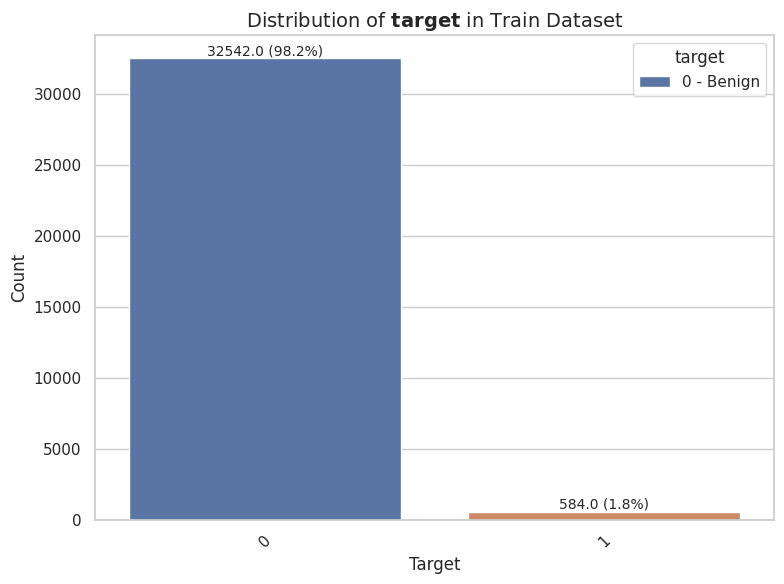

In [12]:
count_plot(df=train_df, 
           column_name='target', 
           title=None,
           labels=['0 - Benign', '1 - Malignant'])

In [13]:
train_df['diagnosis'].unique().tolist()

['unknown',
 'nevus',
 'melanoma',
 'seborrheic keratosis',
 'lentigo NOS',
 'lichenoid keratosis',
 'solar lentigo',
 'cafe-au-lait macule',
 'atypical melanocytic proliferation']

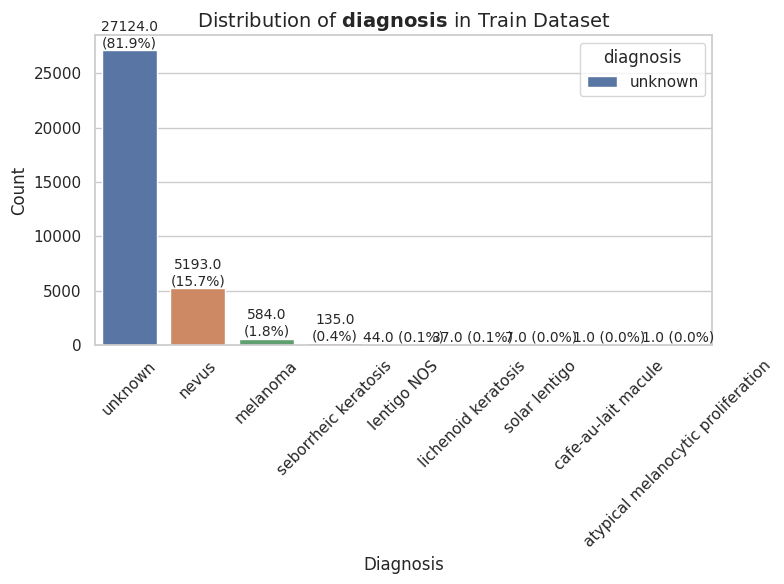

In [14]:
count_plot(df=train_df, 
               column_name='diagnosis', 
               title=None,
               labels=train_df['diagnosis'].unique().tolist())

In [15]:
def boxplot(df, column, hue_column):
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df, x=hue_column, y=column)
    
    # Calculate descriptive statistics
    desc_stats = df.groupby(hue_column)[column].describe()
    
    for i, (group, stats) in enumerate(desc_stats.iterrows()):
        
        mean = stats['mean']
        median = stats['50%']
        std = stats['std']

        x_pos = i
        y_pos = mean + std 
        
        # Add the text to the plot
        text = f"Mean: {mean:.2f}\nMedian: {median:.2f}\nStd: {std:.2f}"
        plt.text(x_pos, y_pos, text, ha='center', va='bottom', fontsize=10, color='black')

    plt.title(f'Distribution of ' + prefix_bold + column + suffix_bold, fontsize=14)
    plt.xlabel(hue_column.capitalize(), fontsize=12)
    plt.ylabel(column.capitalize(), fontsize=12)

    # Show plot
    plt.tight_layout()
    plt.show()

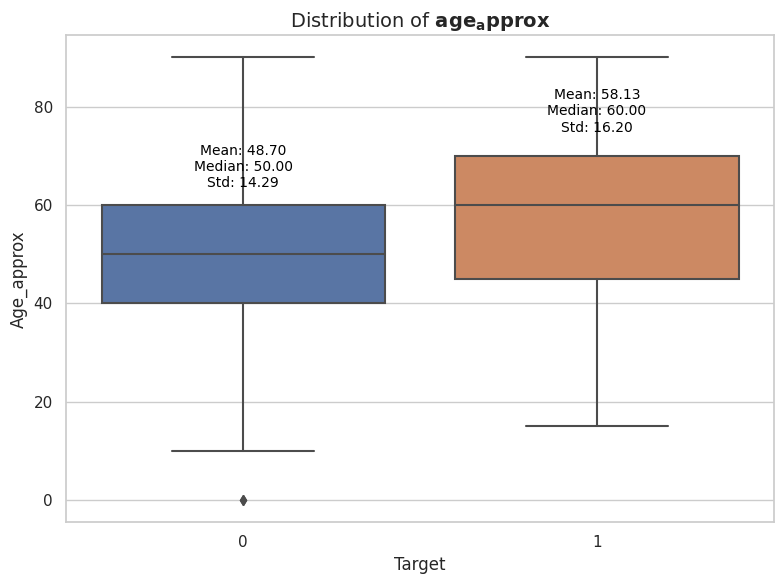

In [16]:
boxplot(train_df, 
        'age_approx', 
        'target')

## Unstructured Data

In [17]:

def plot_image_and_histogram(structured_df:pd.DataFrame, 
                             target_val:int, 
                             col:str,
                             dir_path:str, 
                             subset:str,
                             target_col = 'target',
                             file_format:str = 'jpg',
                             title = 'Image and Histogram'):
    # Patient Information 
    an_image = structured_df.loc[structured_df[target_col]==target_val].sample(1).squeeze()
    image_index = an_image.name

    data_dict =  an_image.to_dict() 
    image_name = an_image[col]
    image_path = f"{dir_path}/{subset}/{image_name}.{file_format}"
    image = Image.open(image_path)

    # Image Information 
    data_dict['index'] = image_index
    data_dict['dir_path'] = dir_path
    data_dict['file_path'] = image_path
    data_dict['mode'] = image.mode
    data_dict['size'] = image.size
    sub_title = []

    key_list = list(data_dict.keys())
    
    for k, v in data_dict.items():
        index_of_key = key_list.index(k)
        if index_of_key == 0:
            sub_title.append(r'$\bf{'+ 'Patient Information'+ '}$')
        if k == 'index':
            sub_title.append(r'$\bf{' + 'Image Information'+ '}$')
        bullet_point = '-' + r'$\bf{' + str(k.replace('_', ' ')) + '}$' ': ' + str(v)
        sub_title.append(bullet_point)
        
    sub_title ="\n".join(sub_title) 

    if image.mode == 'L':
        # Create subplots with 1 row and 2 columns
        fig, axs = plt.subplots(1, 2, figsize=(12, 6))

        
        axs[0].imshow(image, cmap='gray')
        axs[0].set_title(sub_title, loc='left')

        axs[1].hist(image.getdata(), bins=256, color='gray', alpha=0.5, label='Gray', histtype='step')
        axs[1].set_xlabel('Intensity')
        axs[1].set_ylabel('Frequency')
        axs[1].set_title('Histogram of the Grayscale Image')
         # Add big title
        fig.suptitle(title, fontsize=16, fontweight='bold')
        # prevent overlap
        plt.tight_layout()
        plt.show()
    else:
        # For RGB images, split channel
        r, g, b = image.split()
        fig, axs = plt.subplots(1, 2, figsize=(15, 6))
        axs[0].imshow(image)
        axs[0].set_title(sub_title, loc='left')
        axs[1].hist(r.getdata(), bins=256, color='red', alpha=0.5, label='Red', histtype='step')
        axs[1].hist(g.getdata(), bins=256, color='green', alpha=0.5, label='Green', histtype='step')
        axs[1].hist(b.getdata(), bins=256, color='blue', alpha=0.5, label='Blue', histtype='step')
        axs[1].set_xlabel('Intensity')
        axs[1].set_ylabel('Frequency')
        axs[1].set_title('Histogram of the Image Channels')
        axs[1].legend()
        fig.suptitle(title, fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

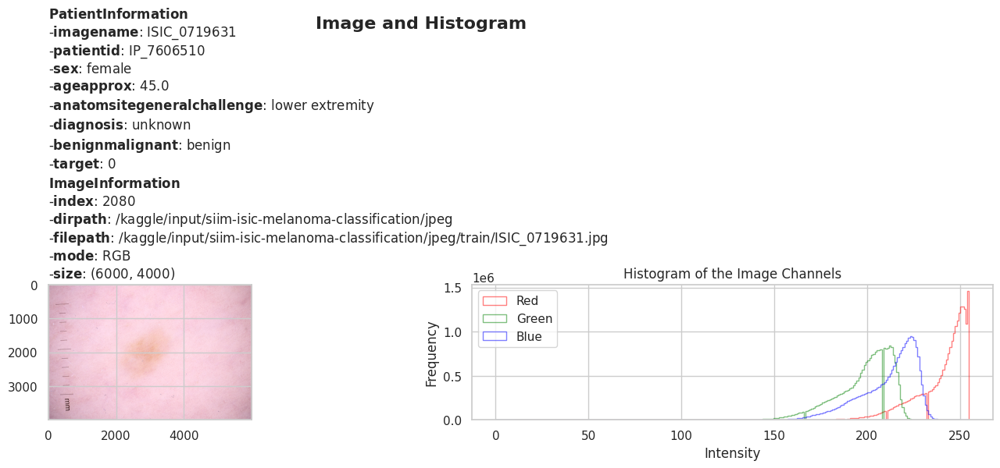

In [18]:
plot_image_and_histogram(structured_df=train_df, 
                             target_val=0, 
                             col='image_name',
                             dir_path=jpeg_path, 
                             subset='train',
                             target_col = 'target',
                             file_format= 'jpg',
                             title = 'Image and Histogram')

In [19]:
def display_image_by_df(structured_df:pd.DataFrame, 
                        target_val:int, 
                        col:str,
                        dir_path:str, 
                        subset:str,
                        target_col = 'target',
                        file_format:str = 'jpg',
                        title = 'Image and Histogram',
                        num_display=16, num_cols=4, cmap='gray', random_mode=False):
    
    n_cols = min(num_cols, num_display)
    n_rows = int(np.ceil(num_display / n_cols))

    n_images = min(num_display, len(structured_df))
    if random_mode:
            if num_display > n_images:
                print("Warning: num_display exceeds the number of available images. Setting num_display to the number of available images.")
                num_display = n_images
            random_indices = np.random.choice(
                n_images, num_display, replace=False)
    else:
        num_display = min(num_display, n_images)
        random_indices = np.arange(num_display)
        
    filtered_df = structured_df.loc[structured_df[target_col]==target_val].sample(num_display)
    # .squeeze()
    
    fig, axes = plt.subplots(
        nrows=n_rows, ncols=n_cols, figsize=(17, 4*n_rows))
    for i, ax in tqdm(enumerate(axes.flatten()),desc='Building...', total=num_display):
        index = random_indices[i]
        if i >= n_images:  # Check if the index exceeds the available number of images
            break
        else:
            an_image = filtered_df.iloc[index]
            
        image_dir = os.path.join(dir_path, subset)
        image_name = an_image[col] 
        image_path = os.path.join(image_dir, f'{image_name}.{file_format}')
        image = Image.open(image_path)
        # Get image details
        image_mode = image.mode
        image_size = image.size  # (width, height)
        num_channels = len(image.getbands()) 
        
        ax.imshow(image, cmap=cmap)
        ax.set_title(f"Target: {an_image[target_col]}\nMode: {image_mode}\nSize: {image_size}\nChannels: {num_channels}',")

        # Add image index as text
        ax.text(0.5, -0.2,
                f'Image Index: {index}', transform=ax.transAxes,
                fontsize=7, ha='center')
        
    plt.suptitle(f"{title} (Displaying {num_display} Images)",
                 fontsize=16, fontweight='bold')
    fig.set_facecolor('white')
    plt.tight_layout() 
    return plt.show()

Building...: 100%|██████████| 30/30 [00:03<00:00,  8.70it/s]


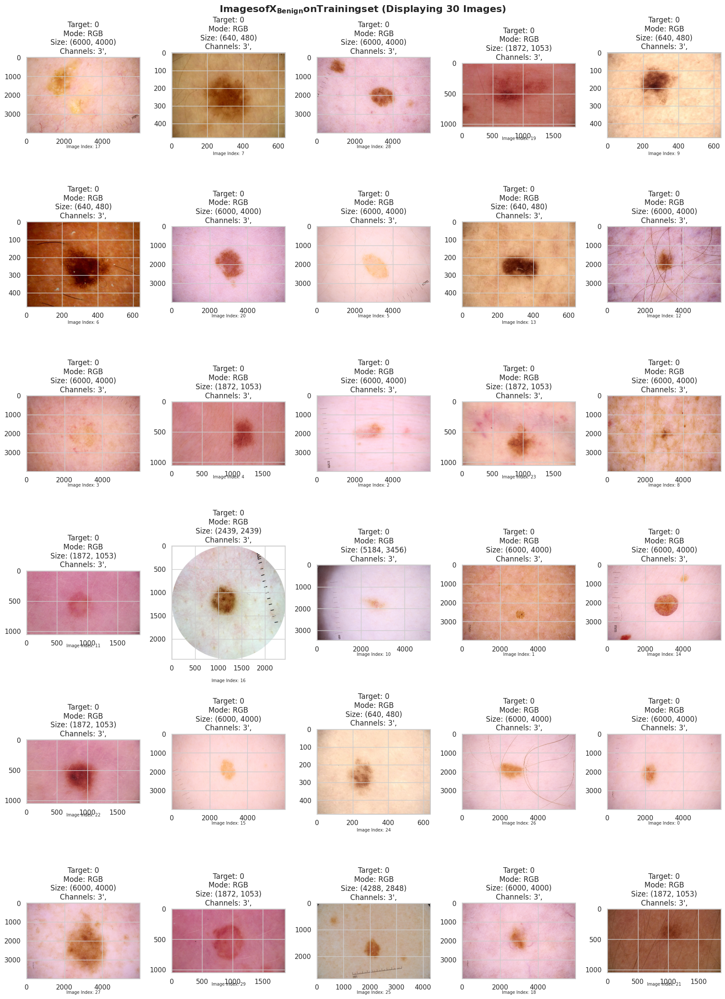

In [20]:
display_image_by_df(structured_df=train_df, 
                        target_val=0, 
                        col='image_name',
                        dir_path=jpeg_path, 
                        subset='train',
                        target_col = 'target',
                        file_format = 'jpg',
                        title = prefix_bold + 'Images of X_{Benign} on Training set' + suffix_bold,
                        num_display=30, num_cols=5, cmap=None, random_mode=True)

Building...: 100%|██████████| 30/30 [00:02<00:00, 13.91it/s]


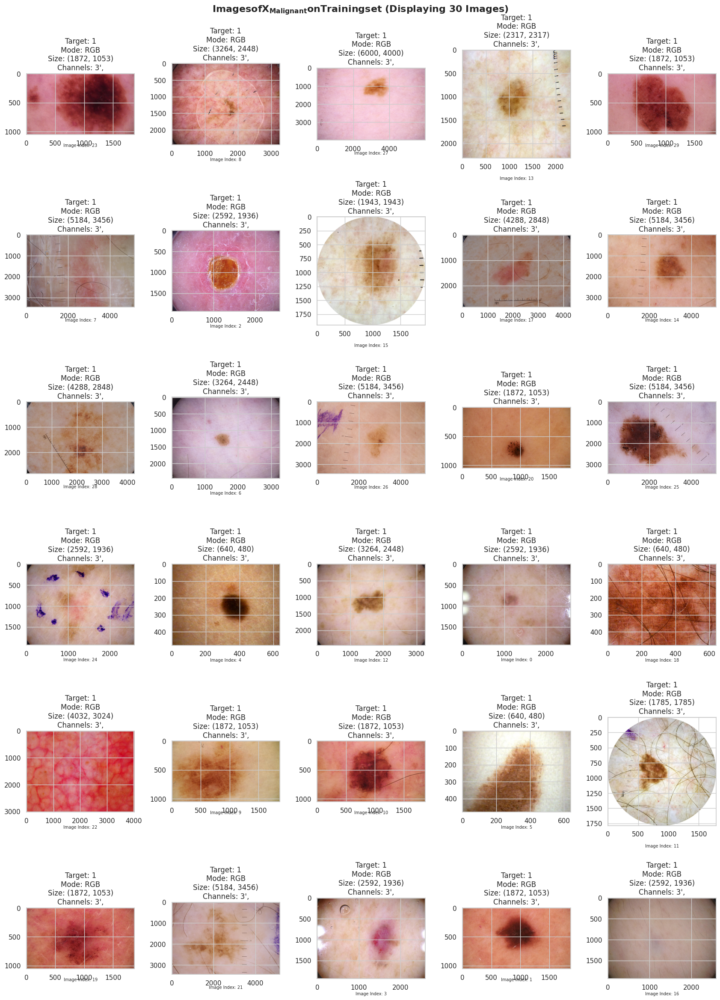

In [21]:
display_image_by_df(structured_df=train_df, 
                        target_val=1, 
                        col='image_name',
                        dir_path=jpeg_path, 
                        subset='train',
                        target_col = 'target',
                        file_format = 'jpg',
                        title = prefix_bold + 'Images of X_{Malignant} on Training set' + suffix_bold,
                        num_display=30, num_cols=5, cmap=None, random_mode=True)

# Data Processing

## Sampling Data
- to rebalance the dataset to match a desired class distribution

In [22]:
def sampling(df, 
             target_col, 
             class_distribution_dict,
             replacement=True):
    balanced_df = pd.DataFrame()
    for cls, count in class_distribution_dict.items():
        class_df = df[df[target_col] == cls]
        if len(class_df) > count:
            # Downsample
            sampled_df = class_df.sample(n=count, random_state=42)
        else:
            # Upsample
            sampled_df = class_df.sample(n=count, replace=replacement, random_state=42)
        balanced_df = pd.concat([balanced_df, sampled_df])
    return balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)

In [23]:
class_distribution = {0: 1000, 1: 584}

balanced_df_without_replacement_df = sampling(
    df=train_df, 
    target_col='target', 
    class_distribution_dict=class_distribution, 
    replacement=False
)

In [24]:
balanced_df_without_replacement_df

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_3296741,IP_5085022,female,55.0,torso,unknown,benign,0
1,ISIC_7229814,IP_6346671,male,25.0,torso,unknown,benign,0
2,ISIC_0327406,IP_7069391,male,40.0,upper extremity,melanoma,malignant,1
3,ISIC_3948906,IP_4369500,male,45.0,torso,unknown,benign,0
4,ISIC_6432495,IP_4356379,female,40.0,upper extremity,unknown,benign,0
...,...,...,...,...,...,...,...,...
1579,ISIC_1388552,IP_4211276,female,80.0,torso,melanoma,malignant,1
1580,ISIC_1375476,IP_9851472,female,35.0,torso,melanoma,malignant,1
1581,ISIC_5874516,IP_4938382,female,25.0,upper extremity,unknown,benign,0
1582,ISIC_6971606,IP_9375901,female,25.0,torso,melanoma,malignant,1


In [25]:
balanced_df_without_replacement_df['target'].value_counts()

target
0    1000
1     584
Name: count, dtype: int64

## Numpize 
- reads .jpg image files and converts them into NumPy arrays 

In [26]:
from numpy import asarray

In [27]:
def numpize(structured_df:pd.DataFrame, 
            col:str,
            dir_path:str, 
            subset:str,
            target_col = 'target',
            file_format:str = 'jpg',
            img_size=(256,256),
            grayscale=False,
            frac=0.5, 
            export_path=None):
    
    image_dir = os.path.join(dir_path, subset)
    image_files = os.listdir(image_dir)
    image_count = len(image_files)
    transformed_images = []
    labels = []
    sampled_df = structured_df.groupby('target').sample(frac=frac, random_state=42)
    
    if export_path:
        os.makedirs(export_path, exist_ok=True)
        
    for index, row in tqdm(structured_df.iterrows(), desc='Transforming...', total=len(structured_df)):
        image_name = row[col]
        image_path = os.path.join(image_dir, f'{image_name}.{file_format}')
        image = Image.open(image_path)
        label = row[target_col]
        if grayscale:
            image = image.convert('L')  # Convert to grayscale
        else:
            image = image.convert('RGB')  # Convert to RGB
            
        resized_image = image.resize(img_size)
        data = np.asarray(resized_image)
        # Achieve into list
        transformed_images.append(data)
        labels.append(label)

    images_numpy_array = np.array(transformed_images)
    labels_numpy_array = np.array(labels)
    if export_path:
        X_npy_filename = os.path.join(export_path, f'X_{subset}.npy')
        y_npy_filename = os.path.join(export_path, f'y_{subset}.npy')
        np.save(X_npy_filename, images_numpy_array)
        np.save(y_npy_filename, labels_numpy_array)
    return images_numpy_array, labels_numpy_array

In [28]:
X_train_np, y_train_np = numpize(structured_df=balanced_df_without_replacement_df, 
                                col='image_name',
                                dir_path=jpeg_path, 
                                subset='train',
                                target_col = 'target',
                                file_format = 'jpg',
                                img_size=(256, 256), 
                                grayscale=False,
                                export_path="/kaggle/working/numpy_images")

Transforming...: 100%|██████████| 1584/1584 [04:20<00:00,  6.09it/s]


In [29]:
X_train_np.shape

(1584, 256, 256, 3)

In [30]:
y_train_np.shape

(1584,)

In [31]:
def show_image(images, target, title, num_display=16, num_cols=4, cmap='gray', random_mode=False):
    '''
    :Parameters
        images (ndarray (n,)): Input data as a numpy array.
        target (ndarray (n,)): Target data as a numpy array.
        title (String): Title of the plot.
        num_display (int): Number of images to display. Default is 16.
        num_cols (int): Number of columns in the plot. Default is 4.
        cmap (str): Color map for displaying images. Default is 'gray'.
        random_mode (bool): If True, display images randomly. If False, display the first num_display images. Default is False.
    '''
    n_images = len(images)
    num_display = min(num_display, n_images)  # Ensure num_display doesn't exceed available images

    n_cols = min(num_cols, num_display)
    n_rows = int(np.ceil(num_display / n_cols))

    if random_mode:
        random_indices = np.random.choice(n_images, num_display, replace=False)
    else:
        random_indices = np.arange(num_display)

    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(17, 4*n_rows))

    for i, ax in enumerate(axes.flatten()):
        if i >= num_display:  # Check if there are no more images to display
            ax.axis('off')  # Turn off unused subplots
            continue

        index = random_indices[i]
        image = images[index]
        ax.imshow(image, cmap=cmap)
        ax.set_title(f"Target: {target[index]}")
        

    plt.subplots_adjust(wspace=0.3, hspace=0.3)  # Adjust spacing between subplots
    plt.suptitle(f"{title} (Displaying {num_display} Images)", fontsize=16, fontweight='bold')
    fig.set_facecolor('white')
    plt.tight_layout()
    plt.show()


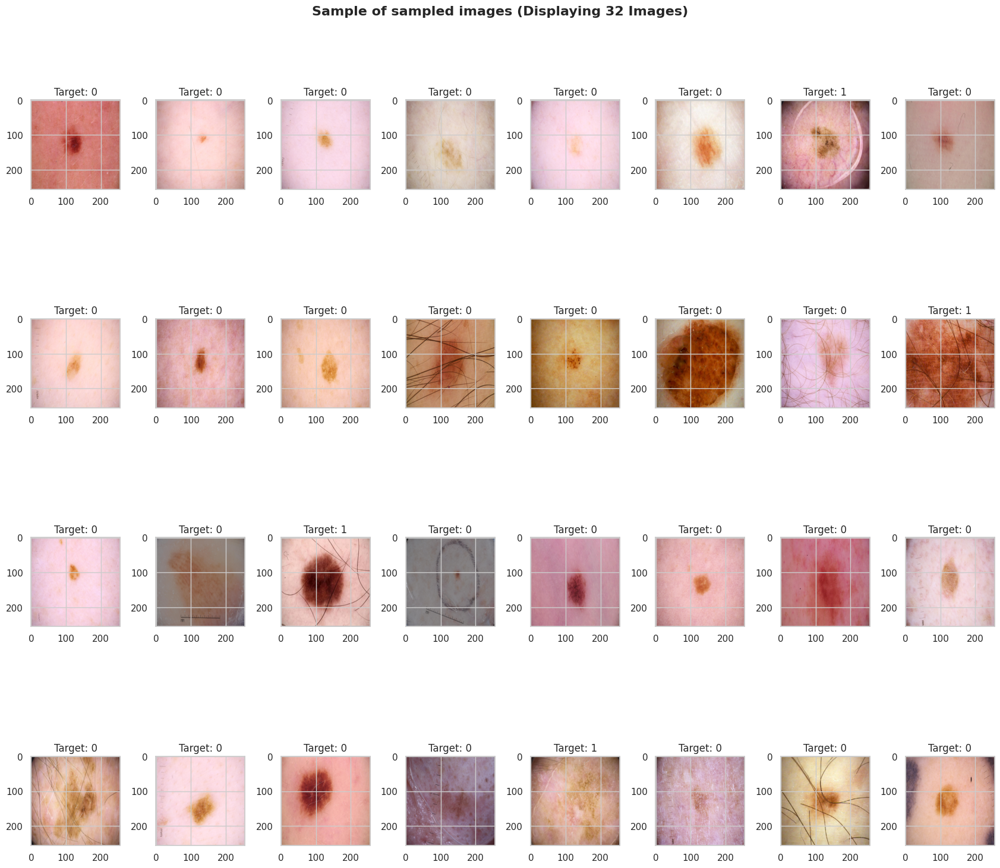

In [32]:
show_image(images=X_train_np, 
           target=y_train_np,
           title='Sample of sampled images',
           num_display=32, 
           num_cols=8, 
           cmap='gray', 
           random_mode=True)

## Distribution of RGB Intensity Distribution Analysis $X_{Benign} \text{ vs } X_{Malignant}$

In [33]:
from skimage import img_as_float
from skimage import exposure

In [34]:
def plot_rgb_intensity_distribution(X_data, y_data, labels=None, title='RGB Intensity Distribution', bins=100):
    
    # Separate 
    benign_indices = np.where(y_data == 0)[0]  # Benign
    malignant_indices = np.where(y_data == 1)[0]  #  Malignant

    # Extract RGB intensities
    benign_rgb = X_data[benign_indices]  # Shape: (n_benign, height, width, 3)
    malignant_rgb = X_data[malignant_indices]  # Shape: (n_malignant, height, width, 3)

    # Flatten intensities for each channel
    benign_r = benign_rgb[:, :, :, 0].ravel()  # Red channel
    benign_g = benign_rgb[:, :, :, 1].ravel()  # Green channel
    benign_b = benign_rgb[:, :, :, 2].ravel()  # Blue channel

    malignant_r = malignant_rgb[:, :, :, 0].ravel()
    malignant_g = malignant_rgb[:, :, :, 1].ravel()
    malignant_b = malignant_rgb[:, :, :, 2].ravel()

    # Descriptive statistics
    data_dict = {
        'Benign Red': benign_r, 'Benign Green': benign_g, 'Benign Blue': benign_b,
        'Malignant Red': malignant_r, 'Malignant Green': malignant_g, 'Malignant Blue': malignant_b
    }
    
    # Compute descriptive statistics
    stats = { key : pd.Series(data).describe().round(2).to_string() for key, data in data_dict.items()}

    # Plot distributions
    channels = ['Red', 'Green', 'Blue']
    data_benign = [benign_r, benign_g, benign_b]
    data_malignant = [malignant_r, malignant_g, malignant_b]

    fig, axes = plt.subplots(3, 1, figsize=(15, 12))

    def create_label(labels, sep=None):
        label_text = ''
        for label in labels:
            index = labels.index(label)
            label_text += prefix_bold + label + suffix_bold 
            if index+1 % 2 == 1:
                label_text += sep 
        return label_text
                
    plt.suptitle(title + create_label(labels, sep=' VS '), fontsize=16, fontweight='bold')

    for i, (channel, benign_data, malignant_data) in enumerate(zip(channels, data_benign, data_malignant)):
        plt.subplot(3, 1, i + 1)
        plt.hist(benign_data, bins=bins, alpha=0.6, color=channel, label='Benign', )
        plt.hist(malignant_data, bins=bins, alpha=0.6, color='black', label='Malignant', )
        plt.title(f'{prefix_bold}{channel}{suffix_bold} Channel Intensity Distribution', fontsize=14)
        plt.xlabel('Intensity Value')
        plt.ylabel('Density')
        plt.legend()
        
        # Add descriptive stats as text
        begin_title = prefix_bold + 'Benign' + suffix_bold
        malignant_title = prefix_bold + 'Malignant' + suffix_bold
        stat_text = f"{begin_title}:\n{stats[f'Benign {channel}']}\n\n{malignant_title}:\n{stats[f'Malignant {channel}']}"
        plt.gca().text(1.02, 0.5, stat_text, transform=plt.gca().transAxes, fontsize=10, verticalalignment='center')
        
    plt.tight_layout(rect=[0, 0, 0.85, 0.95])  # Adjust layout to fit suptitle and stats
    plt.show()

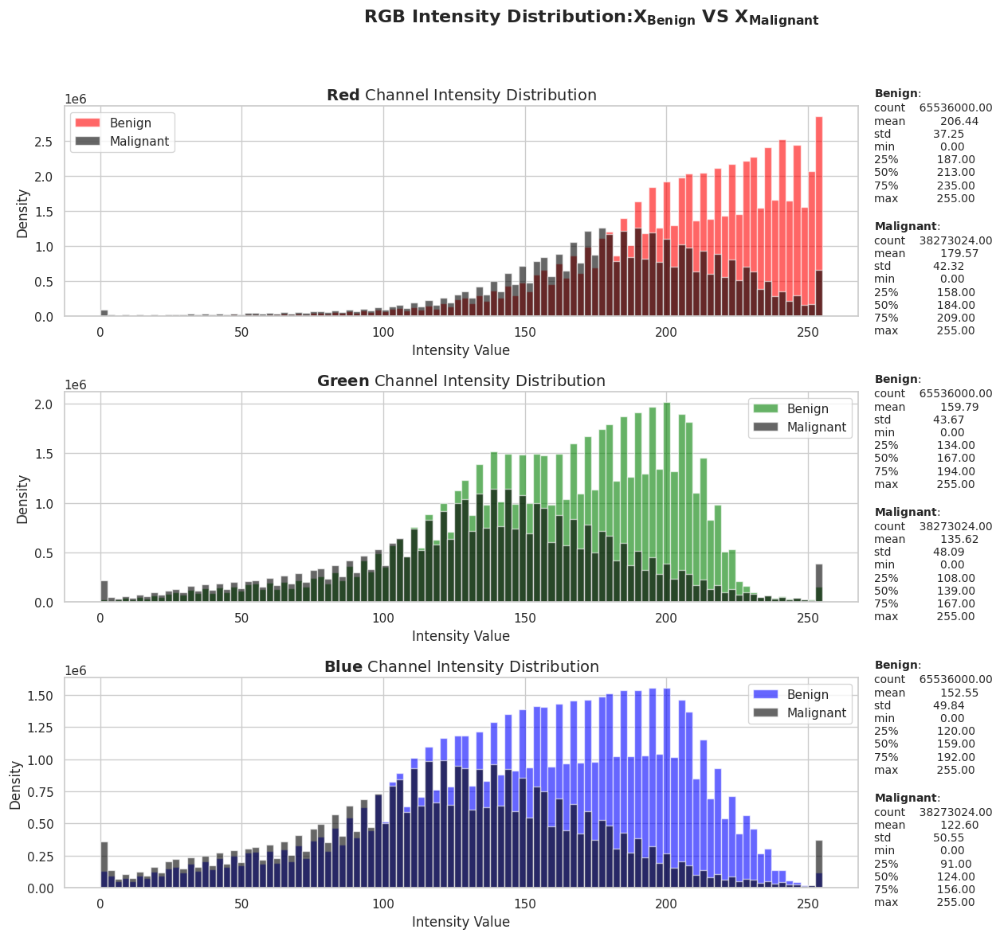

In [35]:
plot_rgb_intensity_distribution(X_train_np, 
                                y_train_np, 
                                title='RGB Intensity Distribution:',
                                labels = ['X_{Benign}', 'X_{Malignant}'])

## Distribution of Gray scale Intensity Distribution Analysis $X_{Benign} \text{ vs } X_{Malignant}$

In [36]:
from skimage import img_as_float
from skimage import exposure
from scipy.stats import mode, skew

In [37]:
def plot_gray_scale_histogram(images, titles, remove_border=False,  percentile=90, bins=55):
    # Display results
    fig, axes = plt.subplots(2, len(images), figsize=(17, 8))

    for i, (title, image) in enumerate(zip(titles, images)):
        if remove_border:
            image = remove_image_border(image)
            
        ax_img, ax_hist, ax_cdf, random_index = img_and_hist(
            image, axes[:, i], bins)
        
        mean_value = np.mean(image)
        median = np.median(image)
        percentil_value = np.percentile(image, percentile)
        std_value = np.std(image)
        min_value = np.min(image)
        max_value = np.max(image)
        population_variance = np.var(image)  # Default: population variance
        pixel_values = image.flatten()
        mode_value, count = mode(pixel_values)
        skewness_value = skew(pixel_values)

        ax_img.set_title('Descriptive statistics of '+r'$\bf{' + f'{title}'+'}$' +
                         f'\nSkew: {skewness_value: .2f}\nMean: {mean_value: .2f}, Median: {median: .2f},\n Mode: {mode_value},\nStd: {std_value: .2f}, Population variance: {population_variance:.2f},\nPercentile {percentile}: {percentil_value:.2f}, Min: {min_value: .2f}, Max: {max_value: .2f}', fontsize=16)
        ax_img.text(0.5, -0.15, f'Image Index: {random_index}\n(Display random image)', transform=ax_img.transAxes,
                    fontsize=10, ha='center')

        y_min, y_max = ax_hist.get_ylim()
        ax_hist.set_title(
            'Distribution of pixel intensities of'+r'$\bf{' + f'{title}'+'}$'+ f'({image.shape[0]})', fontsize=16)
        ax_hist.set_ylabel('Number of pixels')
        ax_hist.set_yticks(np.linspace(0, y_max, 5))

        ax_cdf.set_ylabel('Fraction of total intensity')
        ax_cdf.set_yticks(np.linspace(0, 1, 5))

    plt.suptitle('Gray scale Histogram: Distribution of intensity pixel',
                 fontsize=16, fontweight='bold')
    # Prevent overlap of y-axis labels
    fig.tight_layout()
    plt.show()
    

In [38]:

def img_and_hist(image_data, axes, bins=100):
    image = img_as_float(image_data)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()

    random_index = np.random.randint(0, len(image_data))

    # Display image
    ax_img.imshow(image if image.shape[0] ==1 else image[random_index], cmap=plt.cm.gray)
    ax_img.set_axis_off()

    # Histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity of n sample')
    ax_hist.set_yticks([])

    # Cumulative distribution
    img_cdf, bins = exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_yticks([])

    
    return ax_img, ax_hist, ax_cdf, random_index

In [39]:
def remove_image_border(image, border_size=100):
    transformed_images = []
    for img in image:
        transformed_images.append(img[border_size:-border_size, border_size:-border_size, :])
    return np.array(transformed_images)

In [40]:
# Seperate Target
benign_indices = np.where(y_train_np == 0)[0]  # Benign
malignant_indices = np.where(y_train_np == 1)[0]  #  Malignant

X_train_benign = X_train_np[benign_indices]  
y_train_benign = y_train_np[benign_indices]  

X_train_malignant = X_train_np[malignant_indices]
y_train_malignant = y_train_np[malignant_indices]

images = [X_train_benign, X_train_malignant]
subsets = ['X_{Benign}', 'X_{Malignant}']

In [41]:
X_train_malignant.shape

(584, 256, 256, 3)

In [42]:
balanced_df_without_replacement_df.loc[benign_indices]

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_3296741,IP_5085022,female,55.0,torso,unknown,benign,0
1,ISIC_7229814,IP_6346671,male,25.0,torso,unknown,benign,0
3,ISIC_3948906,IP_4369500,male,45.0,torso,unknown,benign,0
4,ISIC_6432495,IP_4356379,female,40.0,upper extremity,unknown,benign,0
8,ISIC_2946626,IP_2436697,female,45.0,torso,unknown,benign,0
...,...,...,...,...,...,...,...,...
1571,ISIC_6780471,IP_8233849,male,55.0,torso,unknown,benign,0
1573,ISIC_3768806,IP_2618037,female,25.0,torso,unknown,benign,0
1575,ISIC_2584165,IP_6931421,male,30.0,torso,nevus,benign,0
1576,ISIC_6533176,IP_8247808,female,35.0,torso,unknown,benign,0


In [43]:
balanced_df_without_replacement_df.loc[malignant_indices]

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
2,ISIC_0327406,IP_7069391,male,40.0,upper extremity,melanoma,malignant,1
5,ISIC_3475660,IP_1422713,male,75.0,torso,melanoma,malignant,1
6,ISIC_1569119,IP_6120178,male,65.0,torso,melanoma,malignant,1
7,ISIC_0662000,IP_2947490,male,40.0,torso,melanoma,malignant,1
11,ISIC_2351999,IP_1665515,male,80.0,head/neck,melanoma,malignant,1
...,...,...,...,...,...,...,...,...
1578,ISIC_8566006,IP_6624700,male,65.0,torso,melanoma,malignant,1
1579,ISIC_1388552,IP_4211276,female,80.0,torso,melanoma,malignant,1
1580,ISIC_1375476,IP_9851472,female,35.0,torso,melanoma,malignant,1
1582,ISIC_6971606,IP_9375901,female,25.0,torso,melanoma,malignant,1


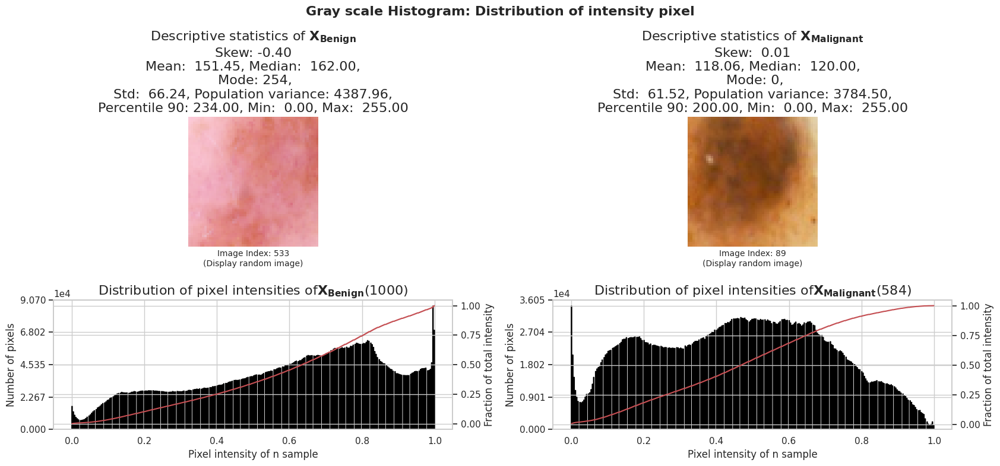

In [44]:
plot_gray_scale_histogram(images=images, 
                          titles=subsets, 
                          remove_border=True,
                          bins=555)

In [45]:
def display_contour_area_distribution(images, threshold_value=100, min_area=200,max_area=2000, percentiles=None):
    contour_areas = []

    for idx, image in enumerate(images):
        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        # Apply threshold
        _, thresh = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY_INV)
        
        # Find contours
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Extract areas of contours
        for contour in contours:
            area = cv2.contourArea(contour)
            if (area >= min_area) and (area <= max_area):
                contour_areas.append(area)
    
    # Default percentiles if not provided
    if percentiles is None:
        percentiles = [0.10, 0.25, 0.5, 0.75, 0.90]  # Default to 25th, 50th (median), and 75th percentiles
    
    # Generate descriptive statistics with custom percentiles
    desc = pd.Series(contour_areas).describe(percentiles=percentiles).round(2).to_string()
    
    # Plot distribution
    plt.figure(figsize=(10, 6))
    plt.hist(contour_areas, bins=50, color='blue', alpha=0.7)
    plt.title('Distribution of Contour Areas', fontsize=16)
    plt.xlabel('Contour Area', fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Add descriptive statistics as text in the plot
    plt.gca().text(
        0.95, 0.95, desc,
        transform=plt.gca().transAxes, ha='right', va='top', fontsize=10,
        bbox=dict(facecolor='white', alpha=0.5)
    )

    plt.show()

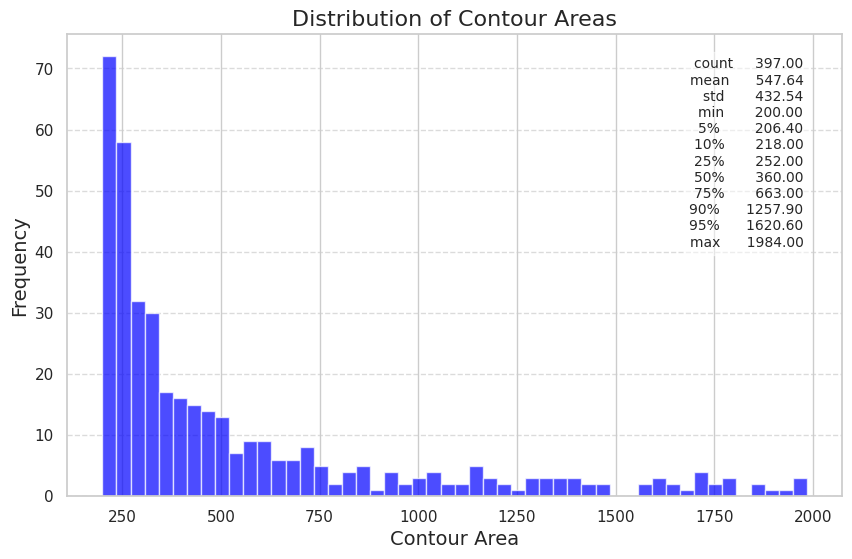

In [46]:

display_contour_area_distribution(X_train_malignant, 
                                  threshold_value=50, 
                                  min_area=200, 
                                  max_area=2000,
                                  percentiles=[0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95])

# Data Processing

## Hair Removal
- to remove hair-like structures from an image using morphological operations, including:
### Steps
1. Convert the image to grayscale:
2. Create a structuring element (kernel):
   - creates a "kernel," a matrix that is used for morphological operations. The size of the kernel is (17, 17), which means it is a 17x17 matrix. kernel = cv2.getStructuringElement(1, (17, 17)) means that it is a rectangular (not elliptical) kernel.

```jsx
# Rectangular Kernel
>>> cv2.getStructuringElement(cv2.MORPH_RECT,(5,5))
array([[1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1]], dtype=uint8)

# Elliptical Kernel
>>> cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
array([[0, 0, 1, 0, 0],
       [1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1],
       [0, 0, 1, 0, 0]], dtype=uint8)

# Cross-shaped Kernel
>>> cv2.getStructuringElement(cv2.MORPH_CROSS,(5,5))
array([[0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0],
       [1, 1, 1, 1, 1],
       [0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0]], dtype=uint8)

```


3. Apply the Blackhat Morphological Operation:
   
    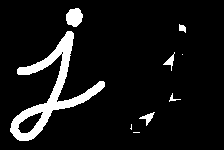

- highlights dark regions in a light background. In this case, it helps to highlight hair-like structures (dark features) on the skin or lighter background.

4. Threshold the image:
- create a binary mask where hair-like structures (highlighted in the blackhat step) are marked.

  
    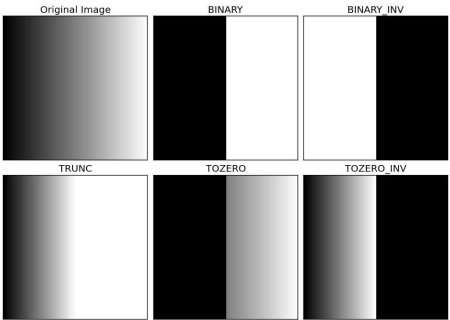

- it is assigned one value (may be white), else it is assigned another value (may be black)
  
5. Inpaint the image:
- Replace those bad marks with its neighbouring pixels, Here we are trying to remove the unwanted hair structures. method fills the masked (hair) regions using nearby pixel information from the original image.


    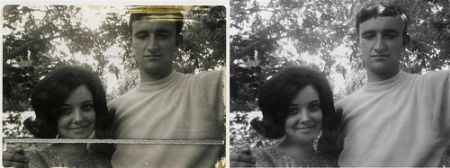

- Reference:
    - [🧬SIIM Melanoma Competition: EDA + Augmentations | ANDRADA](https://www.kaggle.com/code/andradaolteanu/siim-melanoma-competition-eda-augmentations#4.-Preprocess-.csv-files-%F0%9F%93%90)
    - [OpenCV MorphologyEx: Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphologicaal_ops.html)
    - [Thresholding in OpenCV](https://opencv24-python-tutorials.readthedocs.io/en/latest/py_tutorials/py_imgproc/py_thresholding/py_thresholding.html)
    - [Inpainting in OpenCV](https://docs.opencv.org/3.4/df/d3d/tutorial_py_inpainting.html)

In [47]:
def hair_remove(image, dim=512, thresh=5, maxval=255):
    image = np.array(image, dtype=np.uint8)
    grayScale = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(1,(17,17))
    blackhat = cv2.morphologyEx(grayScale, cv2.MORPH_BLACKHAT, kernel)
    _,threshold = cv2.threshold(blackhat,thresh,maxval,cv2.THRESH_BINARY)
    final_image = cv2.inpaint(image,threshold,1,cv2.INPAINT_TELEA)
    final_image = cv2.resize(final_image, (dim, dim))

    return final_image

## Identify Abnormal Images

In [48]:
def compute_image_statistics(image):
    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    
    # Compute image statistics
    stats = {
        'mean_intensity': np.mean(gray),
        'std_intensity': np.std(gray),
        'median_intensity': np.median(gray),
        'percentile_95': np.percentile(gray, 95),
    }
    
    return stats

def abnormal_image_identifier(images, labels, subset, thresholds, mode='all'):
    
        filtered_normal_images = []
        filtered_abnormal_images = []
        filtered_normal_labels = []
        filtered_abnormal_labels = []
        
        for image, label in zip(images, labels):
            # Compute image statistics
            stats = compute_image_statistics(image)
            
            # Apply thresholds based on mode
            if mode == 'all':
                is_abnormal = all(stats[key] > thresholds[key] for key in thresholds if key in stats)
            elif mode == 'any':
                is_abnormal = any(stats[key] > thresholds[key] for key in thresholds if key in stats)
            else:
                raise ValueError("Invalid mode. Use 'all' or 'any'.")
            
            # Classify the image based on the criteria
            if is_abnormal:
                filtered_abnormal_images.append(image)
                filtered_abnormal_labels.append(label)
            else:
                filtered_normal_images.append(image)
                filtered_normal_labels.append(label)
        
        # Print summary
        summary = f"""**Detected Abnormal Images**
    Subset: {subset}
    Amount: {len(filtered_abnormal_images)} images
    """
        print(summary)
        
        return (
            np.array(filtered_normal_images), 
            np.array(filtered_abnormal_images), 
            filtered_normal_labels, 
            filtered_abnormal_labels
        )

In [49]:
constant = 5
thresholds = {
    'mean_intensity': 172,
    'median_intensity': 181,
    'percentile_95': 244
}

# Filter images based on thresholds
X_train_benign_norm, X_train_benign_abnorm, y_train_benign_norm, y_train_benign_abnorm  = abnormal_image_identifier(X_train_benign, 
                                                                                                                    y_train_benign, 
                                                                                                                    subset='Benign', 
                                                                                                                    thresholds=thresholds,
                                                                                                                    mode='all')

**Detected Abnormal Images**
    Subset: Benign
    Amount: 11 images
    


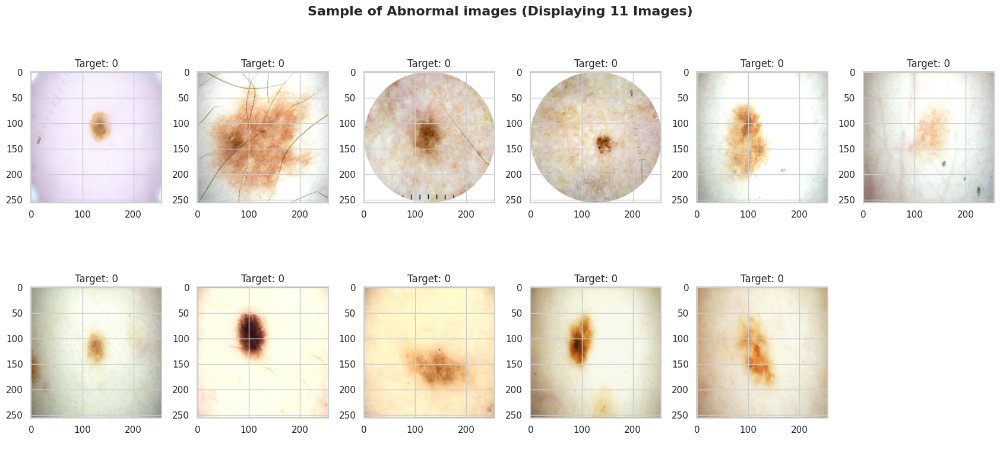

In [50]:
show_image(images=X_train_benign_abnorm, 
           target=y_train_benign_abnorm,
           title='Sample of Abnormal images',
           num_display=12, 
           num_cols=6, 
           cmap='gray', 
           random_mode=True)

## Data Augmentation (Over-sampling) for Class Imbalance
- Problem:  Class Imbalance in Dataset, "Malignant" class has fewer samples compared to the "Benign" class. -> Over-sampling increases the number of images from the minority class ("Malignant") such as rotation, flipping, scaling, and cropping generate varied but realistic images  to avoid bias that model only learn data from the majority class "Benign"

We have subset of data, including:

- Original dataset:
    - $X_{Benign}$: 32542 samples 
    - $X_{Malignant}$: 584 samples
- Sampled dataset: customized target class without replacement
    - $X_{Benign}$: 1000 samples 
    - $X_{Malignant}$: 584 samples

References: 
- [tf.image ](https://www.tensorflow.org/api_docs/python/tf/image)

### Image Transformation
function `transform_image` rotates an image by a random angle and resizes, the operations including:

1. Generates a random angle between -90 and 90 degrees
2. `cv2.getRotationMatrix2D(center, angle, scale=1.0)`
    
    **Affine Transformation Matrix Formula**:
    
    The matrix returned by `cv2.getRotationMatrix2D` is:
    
    $\text{Rotation Matrix} =
    \begin{bmatrix}
    \text{cos}(\theta) \cdot \text{scale} & -\text{sin}(\theta) \cdot \text{scale} & \text{(1 - cos)} \cdot cx + \text{sin} \cdot cy \\
    \text{sin}(\theta) \cdot \text{scale} & \text{cos}(\theta) \cdot \text{scale} & \text{(1 - cos)} \cdot cy - \text{sin} \cdot cx
    \end{bmatrix}$
    
    Where $(cx, cy)$ are the center coordinates.
    
3. `cv2.warpAffine(image, rotation_matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)`
    
    Applies the affine transformation (rotation) to the image.
    
    - **`flags=cv2.INTER_LINEAR`**:
        - Specifies the interpolation method for resizing or rotating the image.

        - **Options**:
            
            - `cv2.INTER_NEAREST`: Nearest-neighbor interpolation (fast but may produce jagged edges).
            - `cv2.INTER_LINEAR`: Bilinear interpolation (default; provides smooth results, suitable for most cases).
            - `cv2.INTER_CUBIC`: Bicubic interpolation (slower but smoother than bilinear).
            - `cv2.INTER_LANCZOS4`: Lanczos interpolation (best for high-quality resizing but slower).
    - **`borderMode=cv2.BORDER_REPLICATE`**:
        - Defines how to handle pixels outside the image boundaries during the transformation.
        - **Options**:
            - `cv2.BORDER_CONSTANT`: Pads with a constant value (e.g., black).
            - `cv2.BORDER_REFLECT`: Mirrors the border pixels.
            - `cv2.BORDER_WRAP`: Wraps around the image.
            - `cv2.BORDER_REPLICATE`: Repeats the edge pixels (default; avoids introducing artifacts near the borders).
              
Reference:
- [Geometric Image Transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)

In [51]:
def transform_image(image, dim=512, angle=10, scale=1.1):
    # Ensure the image is in uint8 format for OpenCV
    image = np.array(image, dtype=np.uint8)

    # Random rotation angle
    angle = np.random.uniform(-angle, angle)

    # Get image dimensions
    h, w = image.shape[:2]
    center = (w // 2, h // 2)

    rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)

    # Perform the rotation
    rotated_image = cv2.warpAffine(image, rotation_matrix, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    # Resize to the desired dimension
    rotated_image = cv2.resize(rotated_image, (dim, dim))

    return rotated_image

In [52]:
def random_fscb(img, dim=512):
    img = tf.image.convert_image_dtype(img, tf.float32)  # range [0, 1]
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_saturation(img, 0.7, 1.3)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_brightness(img, 0.1)
    img = tf.image.resize(img, [dim, dim])   
    img = tf.image.convert_image_dtype(img, tf.uint8).numpy()

    return img


In [53]:
def compute_descriptive_statistics(image):
    stats = {}
    if isinstance(image, tf.Tensor):
        image = image.numpy()
    
    for i, color in enumerate(['Red', 'Green', 'Blue']):
        channel_data = image[:, :, i].flatten()  # Flatten the channel
        stats[color] = pd.Series(channel_data).describe().round(2)
    return stats


def plot_rgb_histograms(image, ax):
    stats = compute_descriptive_statistics(image)

    if isinstance(image, tf.Tensor):
        image = image.numpy()

    # Split the channels
    r, g, b = image[:, :, 0].flatten(), image[:, :, 1].flatten(), image[:, :, 2].flatten()
    
    ax.hist(r, bins=256, color='red', alpha=0.5, label='Red', histtype='step')
    ax.hist(g, bins=256, color='green', alpha=0.5, label='Green', histtype='step')
    ax.hist(b, bins=256, color='blue', alpha=0.5, label='Blue', histtype='step')
    ax.text(0.95, 0.95, 'str(stats)', transform=ax.transAxes, 
                           fontsize=10, verticalalignment='top', horizontalalignment='right',
                           bbox=dict(facecolor='white', alpha=0.5))
    
    ax.set_title("RGB Histogram")
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")
    ax.legend()

### Detect and crop

In [54]:
def detect_crop(image, dim=512, padding=0, threshold_val=10, maxval=255):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    ret, thresh = cv2.threshold(gray, threshold_val, maxval, cv2.THRESH_BINARY)
    contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(contour)
    
    cv2.rectangle(image, (x, y), (x + w, y + h), (255, 0, 0), 2) 

    cropped_image = image[max(y - padding if (y - padding) > 0 else 0, 0):min((y + h + padding) if (y + h + padding) > 0 else 0, image.shape[0]),
                         max(x - padding if (x - padding) > 0 else 0, 0):min(x + w + padding if (x + w + padding) else 0, image.shape[1])]
    cropped_image = cv2.resize(cropped_image, (dim, dim))
    return cropped_image

### Highlight 

In [55]:
from skimage.filters import threshold_otsu
from skimage.morphology import square, closing
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops
from skimage.color import label2rgb

In [56]:
def segmentize(X, return_only_overlay=True):
        X_reshaped = X[:, :, 0]
        # 1 Equalize the image with CLAHE
        X_eq = exposure.equalize_adapthist(
            X_reshaped, clip_limit=0.01, nbins=256)
        gray = cv2.cvtColor(X, cv2.COLOR_BGR2GRAY)
        # 2 Create a binary threshold mask and apply it to the image
        otsu_thresh = threshold_otsu(image=X_eq, nbins=256, hist=None)
        _, binary_image = cv2.threshold(gray, otsu_thresh, 255, cv2.THRESH_BINARY)
        contours, _ = cv2.findContours(binary_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contours_list = []
        for contour in contours:
            area = cv2.contourArea(contour)
            contours_list.append(area)
            
        print(f'Max area of Contour: {area}')
    
        # Invert Binary Image       
        otsu_thresh = X_eq > otsu_thresh
        # 3 Morphological
        # 3.1 Closing
        closing_image = closing(X_eq > otsu_thresh, square(1))
        
        # 5.4 Clean up the borders
        cleared = clear_border(closing_image)

        # Label image regions
        label_image = label(cleared)
        
        # 5.5 Overlay Image
        image_label_overlay = label2rgb(
            label_image,
            image=X,
            bg_label=0,
            bg_color=(0, 0, 0))
        
        if return_only_overlay:
            return image_label_overlay, label_image
        else:
            return X, otsu_thresh, closing_image, cleared, image_label_overlay, label_image

In [57]:

def detect_black_spot_on_skin(image,dim=512, 
                              threshold_value=100, 
                              min_area=200, 
                              max_area= 1500, 
                              padding = 20):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY_INV)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    image_with_spots = image.copy()
    image_center = (image.shape[1] // 2, image.shape[0] // 2)
    bounding_boxes = []
    for contour in contours:
        
        area = cv2.contourArea(contour)
        if (area >= min_area) and (area <= max_area):
            continue
        x, y, w, h = cv2.boundingRect(contour)
        
        box_center = (x + w // 2, y + h // 2)
        distance = np.sqrt((box_center[0] - image_center[0])**2 + (box_center[1] - image_center[1])**2)
        bounding_boxes.append((x, y, w, h, distance))

    # Sort bounding boxes by distance (ascending order), so the closest one is first
    bounding_boxes.sort(key=lambda x: x[4])

    # Select the most middle bounding box (the one with the smallest distance)
    if bounding_boxes:
        x, y, w, h, _ = bounding_boxes[0]
        
        # Draw a red rectangle around the selected bounding box
        x_pad = max(0, x - padding)
        y_pad = max(0, y - padding)
        w_pad = min(image.shape[1] - x_pad, w + 2 * padding)
        h_pad = min(image.shape[0] - y_pad, h + 2 * padding)
        
        cv2.rectangle(image_with_spots, (x, y), (x + w, y + h), (0, 0, 255), 2)  # Red color, thickness 2
        cropped_image = image[y_pad:y_pad + h_pad, x_pad:x_pad + w_pad]
        cropped_image = cv2.resize(cropped_image, (dim, dim))
        return image_with_spots, cropped_image 
    return image_with_spots, image 


In [58]:
X_train_malignant.shape

(584, 256, 256, 3)

Max area of Contour: 261121.0


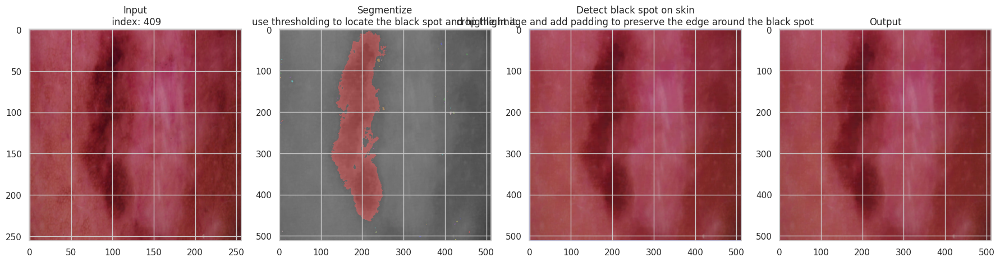

In [59]:
# Note indexes: 42
specified_index = 233
# Sample an image
random_index = np.random.choice(X_train_malignant.shape[0])
sample_image = X_train_malignant[random_index] 

# Sample 4 random images
sample_indices = random.sample(range(X_train_malignant.shape[0]), 4)
sample_images = X_train_malignant[sample_indices]

removed_hair = hair_remove(sample_image)

X_equalized, thresh,  closing_image, cleared, image_label_overlay, label_image = segmentize(
                removed_hair, return_only_overlay=False)
# Based on stats on gray scale histogram plot between benign vs maliagnant
image_with_spots, cropped_image = detect_black_spot_on_skin(removed_hair, 
                                             threshold_value=100,
                                            padding= 200)

fig, axes = plt.subplots(1,4, figsize=(18, 12))


axes[0].imshow(tf.cast(sample_image, tf.uint8))
axes[0].set_title(f'Input\n index: {random_index}')

axes[1].imshow(image_label_overlay)
axes[1].set_title('Segmentize\nuse thresholding to locate the black spot and highlight it.')

axes[2].imshow(image_with_spots)
axes[2].set_title('Detect black spot on skin\ncrop the image and add padding to preserve the edge around the black spot')

axes[3].imshow(cropped_image)
axes[3].set_title('Output')

plt.tight_layout()
plt.show()

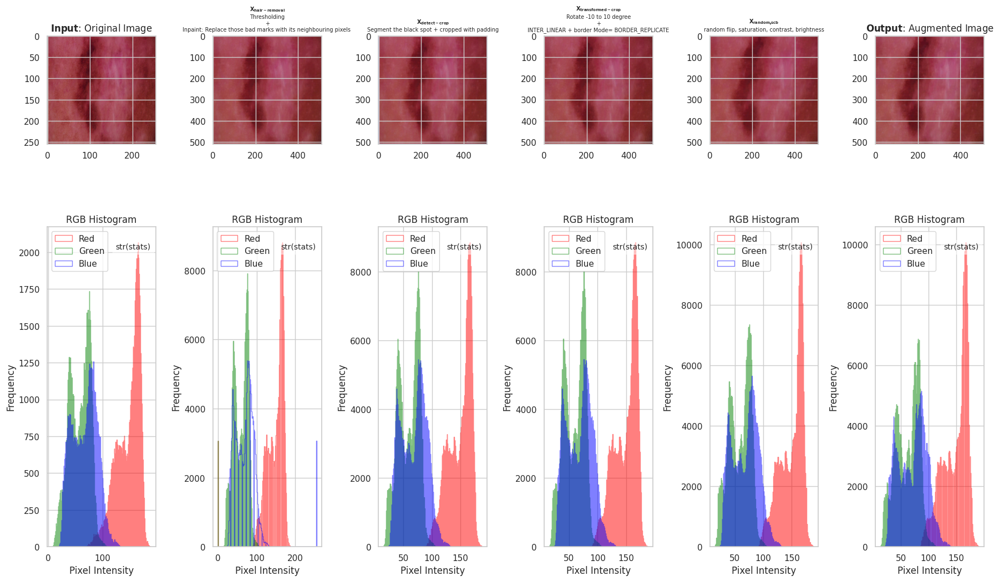

In [60]:
removed_hair = hair_remove(sample_image)

image_with_spots, cropped_image = detect_black_spot_on_skin(removed_hair, 
                                             threshold_value=100,
                                             min_area=200,
                                            padding= 200)

transformed_image = transform_image(cropped_image)
augmented_image = random_fscb(transformed_image)

input_stats = compute_descriptive_statistics(sample_image)
detect_cropped_stat = compute_descriptive_statistics(cropped_image)
transformed_stats = compute_descriptive_statistics(transformed_image)
augmented_stats = compute_descriptive_statistics(augmented_image)

fig, axes = plt.subplots(2, 6, figsize=(18, 12))

axes[0, 0].imshow(tf.cast(sample_image, tf.uint8))
axes[0, 0].set_title(f"{prefix_bold}Input{suffix_bold}: Original Image")


axes[0, 1].imshow(removed_hair)
axes[0, 1].set_title(prefix_bold + 'X_{hair-removal}' + suffix_bold + '\nThresholding\n+\nInpaint: Replace those bad marks with its neighbouring pixels ', fontsize=7)

axes[0, 2].imshow(image_with_spots)
axes[0, 2].set_title(prefix_bold + 'X_{detect-crop}' + suffix_bold + '\nSegment the black spot + cropped with padding', fontsize=7)

axes[0, 3].imshow(cropped_image)
axes[0, 3].set_title(prefix_bold + 'X_{transformed-crop}' + suffix_bold + '\nRotate -10 to 10 degree\n+\nINTER_LINEAR + border Mode= BORDER_REPLICATE', fontsize=7)

axes[0, 4].imshow(transformed_image)
axes[0, 4].set_title(prefix_bold + 'X_{random_fscb}' + suffix_bold + '\nrandom flip, saturation, contrast, brightness', fontsize=7)

axes[0, 5].imshow(augmented_image)
axes[0, 5].set_title(f"{prefix_bold}Output{suffix_bold}: Augmented Image")

plot_rgb_histograms(sample_image, axes[1, 0])
plot_rgb_histograms(image_with_spots, axes[1, 1])
plot_rgb_histograms(removed_hair, axes[1, 2])
plot_rgb_histograms(cropped_image, axes[1, 3])
plot_rgb_histograms(transformed_image, axes[1, 4])
plot_rgb_histograms(augmented_image, axes[1, 5])

plt.tight_layout()
plt.show()

In [61]:
def sampling_transformed_images(X, 
                                methods: list,
                               title:str,
                               n_sample=4,
                               replacement= False):
    sample_indices = np.random.choice(X.shape[0], n_sample,replacement)
    sample_images = [X[index] for index in sample_indices]
    
    n_col = len(methods)
    n_row = len(sample_images)
    fig, axes = plt.subplots(n_row, n_col, figsize=(17, n_row * 4))
    fig.suptitle(title, fontsize=16, weight='bold')
    
    for row, img in enumerate(sample_images):
        transformed_img = None
        for col, method in enumerate(methods):
            if method.__name__ == 'detect_black_spot_on_skin':
                spotted_transformed_img, transformed_img = method(transformed_img)
                axes[row, col].imshow(spotted_transformed_img)
            else:
                if transformed_img is None:
                    transformed_img = method(img)
                else:
                    transformed_img = method(transformed_img)
                axes[row, col].imshow(transformed_img)
            arguments = locals()
            
            fn_name_replaced = method.__name__.replace('_', '-')
            axes[row, col].set_title(prefix_bold + "X_{" + fn_name_replaced + '}' + suffix_bold + f'\n{arguments}')
    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout rect to leave space for suptitle
    plt.show()

In [ ]:
sampling_transformed_images(X_train_malignant, 
                            methods=[hair_remove, detect_black_spot_on_skin, transform_image, random_fscb],
                            title="Comparison of Original and Transformed Images Sequencially",
                            n_sample=10)

In [ ]:
asdas

In [ ]:
def augment_images(X, y, n_sample, methods = [transform_image, random_fscb], dim=512, augment=True):

    augmented_images = []
    augmented_labels = []
    
    for _ in tqdm(range(n_sample), desc='Augmenting...', total=n_sample):
        for img, label in zip(X, y):
            augment_method = random.choice(methods)

            img = augment_method(img, dim=dim)
            augmented_images.append(img)
            augmented_labels.append(label)
            if len(augmented_images) >= n_sample:
                break
    
    # Convert to numpy arrays
    augmented_images = np.array(augmented_images[:n_sample])
    augmented_labels = np.array(augmented_labels[:n_sample])
    
    return augmented_images, augmented_labels

In [ ]:
plot_gray_scale_histogram(images=[X_train_malignant_scaled, X_train_malignant], 
                          titles=['X_{maliagnant+scaled}', 'X_{malignant}'], 
                          bins=555)

In [ ]:
X_train_malignant_augmented, y_train_malignant_augmented  = augment_images(X_train_malignant, 
                                                                           y_train_malignant, 
                                                                           1000,
                                                                           methods = [transform_image, random_fscb, hair_remove])
print(f"Augmented dataset shape: {X_train_malignant_augmented.shape}")

In [ ]:
X_train_malignant.shape

In [ ]:
show_image(images=X_train_malignant_augmented[584:-1], 
           target=y_train_malignant_augmented[584:-1],
           title='After Augmentation images of $X_{malignant + augmented}$',
           num_display=64, 
           num_cols=8, 
           cmap='gray', 
           random_mode=False)

In [ ]:
plot_gray_scale_histogram(images=[X_train_malignant_augmented, X_train_malignant], 
                          titles=['X_{maliagnant+augmented}', 'X_{malignant}'], 
                          bins=555)

In [ ]:
asdas


# 4. Exploratory Data Analysis (EDA) for the SIIM-ISIC Melanoma Classification

## 4.1 Type of $X_{benign}$ vs $X_{malignant}$ Anatom site general challenge
- `anatom_site_general_challenge` - location of imaged site, represents the general body location where the lesion is located.

### 4.1.1 $X_{benign}$ Anatom site general challenge

In [ ]:
balanced_df_without_replacement_df

In [ ]:
balanced_df_without_replacement_df.loc[benign_indices]['anatom_site_general_challenge'].value_counts()

In [ ]:
value_counts = balanced_df_without_replacement_df.loc[benign_indices]['anatom_site_general_challenge'].value_counts()
value_counts.plot(kind='bar')
for i, count in enumerate(value_counts):
    plt.text(i, count + 5, str(count), ha='center', va='bottom', fontsize=10)
plt.title('Distribution of Anatomical Sites (Benign Cases)')
plt.ylabel('Count')
plt.xlabel('Anatomical Site')
plt.show()

#### Get Top 3 Benign `anatom_site_general_challenge`

In [ ]:
top_3_sites_benign = balanced_df_without_replacement_df.loc[benign_indices, 'anatom_site_general_challenge'].value_counts().head(3).index
top_3_sites_benign.to_list()

#### Get indices

In [ ]:
indices_torso = balanced_df_without_replacement_df.loc[benign_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[0]].index
indices_lower_extremity = balanced_df_without_replacement_df.loc[benign_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[1]].index
indices_upper_extremity = balanced_df_without_replacement_df.loc[benign_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[2]].index

In [ ]:
X_train_benign_torso = X_train_np[indices_torso]  
y_train_benign_torso = y_train_np[indices_torso]

X_train_benign_lower_extremity = X_train_np[indices_lower_extremity]  
y_train_benign_lower_extremity = y_train_np[indices_lower_extremity]

X_train_benign_upper_extremity = X_train_np[indices_upper_extremity]  
y_train_benign_upper_extremity = y_train_np[indices_upper_extremity]

In [ ]:
plot_gray_scale_histogram(images=[X_train_benign_torso, X_train_benign_lower_extremity,X_train_benign_upper_extremity], 
                          titles=['X_{benign+torso}', 'X_{benign+lower-extremity}', 'X_{benign+upper-extremity}'], 
                          bins=555)

#### Explanation:
- $X_{benign + torso}$: X?????
- $X_{X + X}$: X?????

### 4.1.2 $X_{malignant}$ Anatom site general challenge

In [ ]:
type_of_diagnosis_malignant = balanced_df_without_replacement_df.loc[malignant_indices]['anatom_site_general_challenge'].value_counts()
type_of_diagnosis_malignant

In [ ]:
value_counts = balanced_df_without_replacement_df.loc[malignant_indices]['anatom_site_general_challenge'].value_counts()
value_counts.plot(kind='bar')
for i, count in enumerate(value_counts):
    plt.text(i, count + 5, str(count), ha='center', va='bottom', fontsize=10)
plt.title('Distribution of Anatomical Sites (Malignant Cases)')
plt.ylabel('Count')
plt.xlabel('Anatomical Site')
plt.show()

In [ ]:
top_3_sites_malignant = balanced_df_without_replacement_df.loc[malignant_indices, 'anatom_site_general_challenge'].value_counts().head(3).index
top_3_sites_malignant.to_list()

In [ ]:
indices_torso = balanced_df_without_replacement_df.loc[malignant_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[0]].index
indices_lower_extremity = balanced_df_without_replacement_df.loc[malignant_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[1]].index
indices_upper_extremity = balanced_df_without_replacement_df.loc[malignant_indices][balanced_df_without_replacement_df['anatom_site_general_challenge'] == top_3_sites[2]].index

In [ ]:
X_train_malignant_torso = X_train_np[indices_torso]  
y_train_malignant_torso = y_train_np[indices_torso]

X_train_malignant_lower_extremity = X_train_np[indices_lower_extremity]  
y_train_malignant_lower_extremity = y_train_np[indices_lower_extremity]

X_train_malignant_upper_extremity = X_train_np[indices_upper_extremity]  
y_train_malignant_upper_extremity = y_train_np[indices_upper_extremity]

In [ ]:
plot_gray_scale_histogram(images=[X_train_malignant_torso, X_train_malignant_lower_extremity,X_train_malignant_upper_extremity], 
                          titles=['X_{malignant+torso}', 'X_{malignant+lower-extremity}', 'X_{malignant+upper-extremity}'], 
                          bins=555)

#### Explanation:
- $X_{maligant + torso}$: is the 1st freq of `anatom_site_general_challenge`
    - Meadian: 150.00 represent that 
- $X_{X + X}$: X?????

In [ ]:
aaaa

## 4.2 Age approximation Distribution of $X_{benign}$ and  $X_{malignant}$ 
- `age_approx` - approximate patient age at time of imaging

In [ ]:
balanced_df_without_replacement_df.boxplot(
    column='age_approx', 
    by='target', 
    grid=False
)

In [ ]:
train_df

In [ ]:
balanced_df_without_replacement_df.loc[malignant_indices]

# Modeling

# 